# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** RENDIKA TAHIR AHMAD
- **Email:** rendikatahirahmad@gmail.com
- **ID ASAH Dicoding:** ds012b6y1538

## Menentukan Pertanyaan Bisnis
1. **Pertanyaan 1 (SMART):** Kategori produk apa yang menghasilkan total pendapatan (*revenue*) tertinggi dan terendah di antara 10 kategori teratas maupun terbawah selama periode tahun penuh 2017 hingga Agustus 2018 untuk menentukan prioritas alokasi stok dan kampanye promosi kuartal berikutnya?
   - *Specific:* Fokus pada performa *revenue* per kategori produk.
   - *Measurable:* Diukur menggunakan total nilai transaksi (`price`) dalam mata uang Real Brasil (BRL).
   - *Action-Oriented:* Menjadi dasar keputusan alokasi stok dan fokus promosi kategori produk.
   - *Relevant:* Pendapatan produk berkaitan langsung dengan pertumbuhan GMV *e-commerce*.
   - *Time-bound:* Dibatasi pada transaksi berstatus *delivered* periode Januari 2017 – Agustus 2018.

2. **Pertanyaan 2 (SMART):** Bagaimana persentase keterlambatan pengiriman pesanan (*delivery delay rate*) di 10 negara bagian (*state*) dengan volume pesanan tertinggi selama periode Januari 2017 hingga Agustus 2018 guna mengevaluasi kinerja mitra logistik wilayah?
   - *Specific:* Fokus pada tingkat keterlambatan pengiriman berdasarkan negara bagian pelanggan (`customer_state`).
   - *Measurable:* Diukur dari persentase pesanan yang tiba melewati tanggal estimasi (`order_delivered_customer_date > order_estimated_delivery_date`) dan rata-rata hari keterlambatannya.
   - *Action-Oriented:* Memberikan arahan wilayah mana yang memerlukan negosiasi ulang SLA atau penambahan mitra ekspedisi.
   - *Relevant:* Ketepatan waktu pengiriman sangat memengaruhi retensi dan kepuasan pelanggan.
   - *Time-bound:* Periode Januari 2017 – Agustus 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

## Data Wrangling

### Gathering Data
Pada tahap ini, kita memuat tabel-tabel yang relevan dari E-Commerce Public Dataset ke dalam DataFrame Pandas.

In [2]:
customers_df = pd.read_csv("data/customers_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
product_translation_df = pd.read_csv("data/product_category_name_translation.csv")

orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight Gathering Data:**
- Data berhasil dimuat dari 5 tabel utama yang saling berelasi: `customers_df` (data lokasi pelanggan), `orders_df` (status dan waktu pesanan), `order_items_df` (detail harga dan barang per pesanan), `products_df` (kategori produk dalam bahasa Portugis), dan `product_translation_df` (terjemahan nama kategori ke bahasa Inggris).

### Assessing Data
Pada tahap ini, kita memeriksa tipe data, *missing values*, data duplikat, serta ketidaksesuaian nilai (*inaccurate value* / *outlier*) pada masing-masing tabel.

In [3]:
print("=== INFO ORDERS ===")
print(orders_df.info())
print("\nMissing values pada orders_df:\n", orders_df.isna().sum())
print("Duplikat pada orders_df:", orders_df.duplicated().sum())

print("\n=== INFO ORDER ITEMS ===")
print(order_items_df.info())
print("\nStatistik deskriptif order_items_df:\n", order_items_df.describe())

print("\n=== INFO PRODUCTS ===")
print("Missing values pada products_df:\n", products_df.isna().sum())
print("Duplikat pada products_df:", products_df.duplicated().sum())

=== INFO ORDERS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None

Missing values pada orders_df:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivere

**Insight Assessing Data & Rencana Solusi:**
1. **Inaccurate Data Type (Tipe Data Tidak Sesuai):** Kolom-kolom waktu pada `orders_df` seperti `order_purchase_timestamp`, `order_delivered_customer_date`, dan `order_estimated_delivery_date` masih bertipe `object` (string).
   - *Solusi:* Mengonversi seluruh kolom tanggal tersebut menjadi tipe data `datetime` menggunakan `pd.to_datetime()`.
2. **Missing Values (Nilai Kosong):**
   - Terdapat *missing values* pada `orders_df` di kolom `order_delivered_customer_date` (2.965 baris) karena sebagian pesanan berstatus *canceled*, *invoiced*, atau *shipped* (belum sampai).
   - Terdapat *missing values* pada `products_df` di kolom `product_category_name` (610 baris).
   - *Solusi:* Memfilter analisis hanya pada pesanan berstatus `delivered` yang berada di rentang Januari 2017 – Agustus 2018 dan menghapus baris yang masih memiliki `order_delivered_customer_date` kosong, serta mengisi `product_category_name` yang kosong dengan label `"unknown"`.

### Cleaning Data
Menjalankan perbaikan data sesuai solusi yang telah dirancang pada tahap Assessing Data.

In [4]:
# 1. Mengubah tipe data kolom tanggal menjadi datetime
datetime_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Filter pesanan delivered pada periode Januari 2017 - Agustus 2018 & hapus missing delivery date
clean_orders_df = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_df["order_purchase_timestamp"] <= "2018-08-31 23:59:59")
].dropna(subset=["order_delivered_customer_date", "order_estimated_delivery_date"]).copy()

# 3. Membuat kolom indikator keterlambatan pengiriman (is_delayed & delay_days)
clean_orders_df["delay_days"] = (
    clean_orders_df["order_delivered_customer_date"].dt.normalize() -
    clean_orders_df["order_estimated_delivery_date"].dt.normalize()
).dt.days
clean_orders_df["is_delayed"] = clean_orders_df["delay_days"] > 0

# 4. Menangani missing value pada kategori produk dan menerjemahkannya ke bahasa Inggris
products_clean_df = pd.merge(
    products_df, product_translation_df, on="product_category_name", how="left"
)
products_clean_df["product_category_name_english"] = products_clean_df["product_category_name_english"].fillna("unknown")

print("Jumlah pesanan bersih (delivered, Jan 2017 - Agu 2018):", len(clean_orders_df))

Jumlah pesanan bersih (delivered, Jan 2017 - Agu 2018): 96203


**Insight Cleaning Data:**
- Seluruh kolom tanggal pada `orders_df` telah berhasil dikonversi menjadi `datetime`.
- Setelah difilter pada pesanan berstatus `delivered` selama Januari 2017 – Agustus 2018 dan dihapus baris tanpa tanggal pengiriman valid, data siap digabungkan tanpa *missing values* yang mengganggu perhitungan *revenue* maupun keterlambatan pengiriman.

## Exploratory Data Analysis (EDA)

### Explore Data Gabungan (`all_df`)
Menggabungkan seluruh tabel bersih menjadi satu DataFrame utama (`all_df`) untuk mengeksplorasi performa kategori produk dan keterlambatan pengiriman per wilayah.

In [5]:
# Menggabungkan semua tabel
all_df = pd.merge(clean_orders_df, order_items_df, on="order_id", how="inner")
all_df = pd.merge(all_df, products_clean_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
all_df = pd.merge(all_df, customers_df, on="customer_id", how="left")

# Simpan main_data.csv ke folder dashboard untuk digunakan oleh Streamlit
all_df.to_csv("dashboard/main_data.csv", index=False)

# 1. Eksplorasi Revenue per Kategori Produk
category_rev_df = all_df.groupby("product_category_name_english").agg(
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count"),
    total_revenue=("price", "sum")
).reset_index().sort_values(by="total_revenue", ascending=False)

print("Top 5 Kategori Berdasarkan Revenue:")
display(category_rev_df.head(5))
print("\nBottom 5 Kategori Berdasarkan Revenue:")
display(category_rev_df.tail(5))

# 2. Eksplorasi Keterlambatan Pengiriman per Negara Bagian (State) pada niveau Order
order_level_df = all_df.drop_duplicates(subset=["order_id"])
state_delay_df = order_level_df.groupby("customer_state").agg(
    total_orders=("order_id", "nunique"),
    delayed_orders=("is_delayed", "sum"),
    avg_delay_days=("delay_days", lambda x: x[x > 0].mean())
).reset_index()
state_delay_df["delay_rate_pct"] = (state_delay_df["delayed_orders"] / state_delay_df["total_orders"]) * 100

# Ambil 10 state dengan total pesanan terbanyak, urutkan dari delay_rate_pct tertinggi
top10_states_delay = state_delay_df.sort_values(by="total_orders", ascending=False).head(10)
top10_states_delay = top10_states_delay.sort_values(by="delay_rate_pct", ascending=False)
print("\nTingkat Keterlambatan pada 10 State dengan Pesanan Terbanyak:")
display(top10_states_delay)

Top 5 Kategori Berdasarkan Revenue:


,product_category_name_english,total_orders,total_items,total_revenue
43,health_beauty,8610,9422,1229557.50
71,watches_gifts,5489,5853,1163187.91
7,bed_bath_table,9267,10945,1022955.77
65,sports_leisure,7512,8413,952661.40
15,computers_accessories,6517,7631,887944.60



Bottom 5 Kategori Berdasarkan Revenue:


,product_category_name_english,total_orders,total_items,total_revenue
35,flowers,29,33,1110.04
46,home_comfort_2,24,30,760.27
11,cds_dvds_musicals,12,14,730.00
29,fashion_childrens_clothes,7,7,519.95
61,security_and_services,2,2,283.29



Tingkat Keterlambatan pada 10 State dengan Pesanan Terbanyak:


,customer_state,total_orders,delayed_orders,avg_delay_days,delay_rate_pct
4,BA,3253,396,12.022727,12.173378
18,RJ,12310,1495,13.522408,12.144598
7,ES,1992,214,11.299065,10.742972
23,SC,3537,291,8.312715,8.227311
8,GO,1950,128,11.367188,6.564103
22,RS,5327,325,10.240000,6.100995
6,DF,2074,118,7.415254,5.689489
10,MG,11319,519,8.400771,4.585211
25,SP,40399,1817,8.316456,4.497636
17,PR,4903,199,8.321608,4.058740


**Insight Exploratory Data Analysis:**
- Kategori **`health_beauty`** menghasilkan pendapatan tertinggi (lebih dari 1,2 juta BRL), diikuti oleh **`watches_gifts`** dan **`bed_bath_table`**. Sebaliknya, kategori **`security_and_services`** menghasilkan pendapatan paling rendah.
- Di antara 10 negara bagian (*state*) dengan volume pesanan tertinggi, negara bagian **RJ (Rio de Janeiro)** dan **BA (Bahia)** memiliki persentase keterlambatan pengiriman paling tinggi (di atas 11%), jauh lebih tinggi dibandingkan **SP (São Paulo)** yang hanya sekitar 4–5%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa yang menghasilkan total pendapatan (revenue) tertinggi dan terendah selama periode Januari 2017 hingga Agustus 2018?

C:\Users\Asus\AppData\Local\Temp\ipykernel_29024\1623674359.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Asus\AppData\Local\Temp\ipykernel_29024\1623674359.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


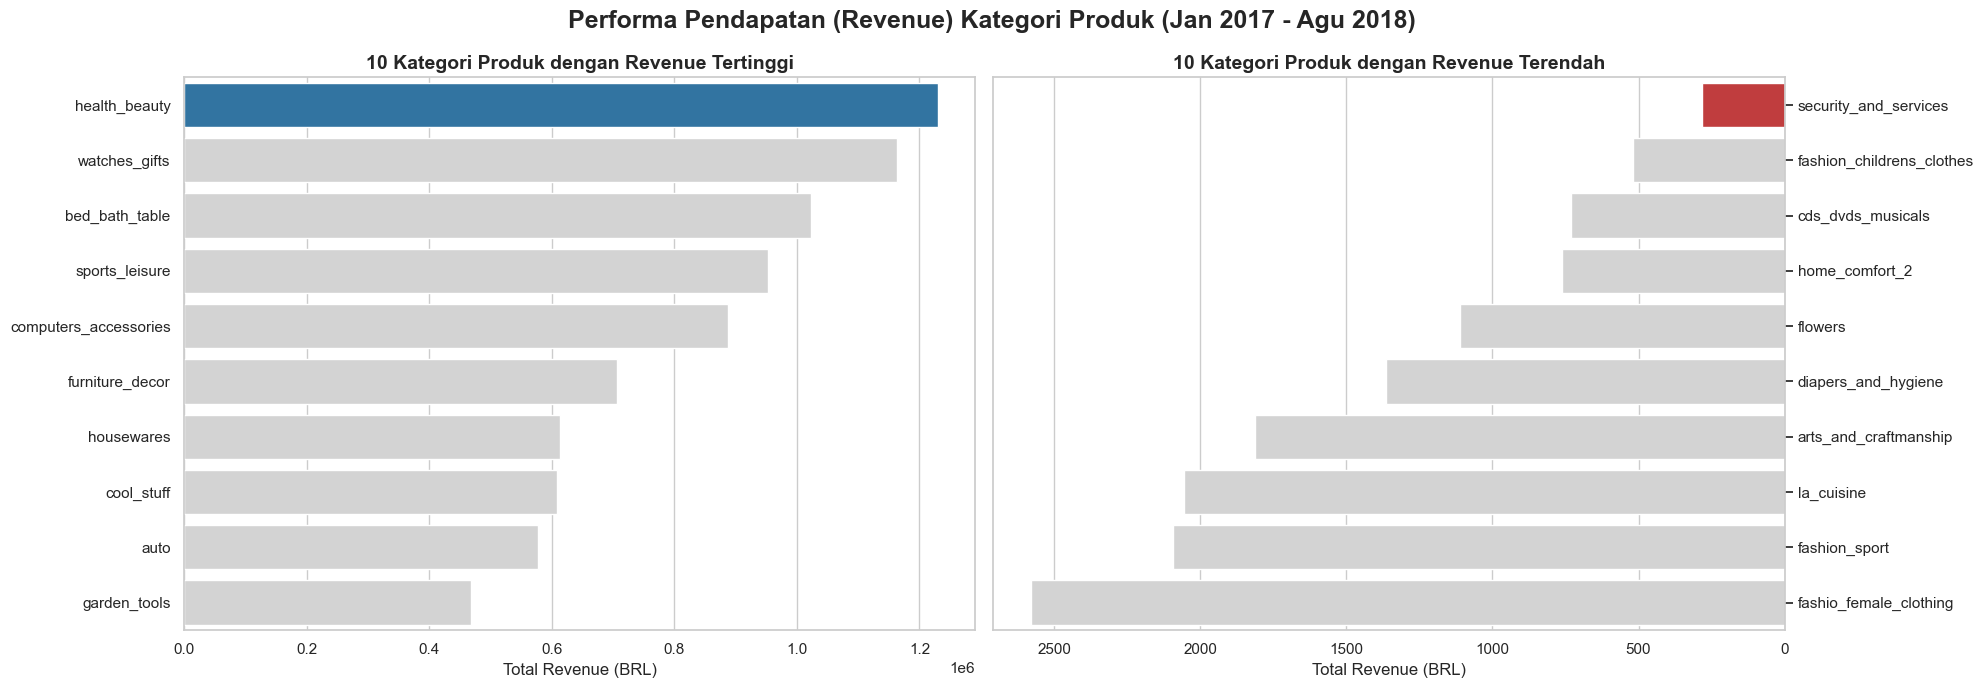

In [6]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 7))

colors_top = ["#1f77b4", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3"]
colors_bottom = ["#d62728", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3", "#d3d3d3"]

sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_rev_df.head(10),
    palette=colors_top,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[0].set_title("10 Kategori Produk dengan Revenue Tertinggi", loc="center", fontsize=14, fontweight="bold")

sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_rev_df.sort_values(by="total_revenue", ascending=True).head(10),
    palette=colors_bottom,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()
ax[1].set_title("10 Kategori Produk dengan Revenue Terendah", loc="center", fontsize=14, fontweight="bold")

plt.suptitle("Performa Pendapatan (Revenue) Kategori Produk (Jan 2017 - Agu 2018)", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana persentase keterlambatan pengiriman pesanan di 10 negara bagian dengan volume pesanan tertinggi selama periode Januari 2017 hingga Agustus 2018?

C:\Users\Asus\AppData\Local\Temp\ipykernel_29024\1995919660.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


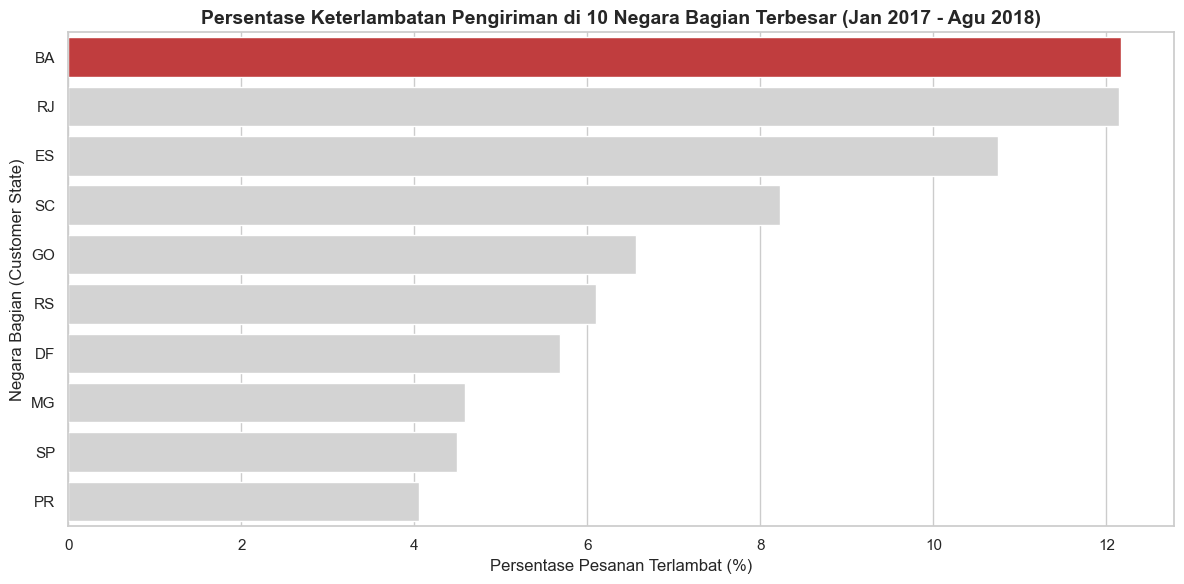

In [7]:
plt.figure(figsize=(12, 6))
colors_delay = ["#d62728" if i == 0 else "#d3d3d3" for i in range(len(top10_states_delay))]

sns.barplot(
    x="delay_rate_pct",
    y="customer_state",
    data=top10_states_delay,
    palette=colors_delay
)
plt.title("Persentase Keterlambatan Pengiriman di 10 Negara Bagian Terbesar (Jan 2017 - Agu 2018)", fontsize=14, fontweight="bold")
plt.xlabel("Persentase Pesanan Terlambat (%)", fontsize=12)
plt.ylabel("Negara Bagian (Customer State)", fontsize=12)
plt.tight_layout()
plt.show()

**Insight Visualization & Explanatory Analysis:**
- Visualisasi Pertama memperlihatkan bahwa kontribusi *revenue* sangat terkonsentrasi pada kategori `health_beauty`, `watches_gifts`, dan `bed_bath_table`.
- Visualisasi Kedua menunjukkan adanya masalah distribusi logistik yang signifikan di wilayah luar São Paulo, khususnya di **RJ (Rio de Janeiro)** dan **BA (Bahia)** yang tingkat keterlambatannya menembus dua digit.

## Analisis Lanjutan (RFM Analysis & Customer Segmentation)
**Tujuan Analisis:**
Mengelompokkan pelanggan unik (`customer_unique_id`) menggunakan metode **RFM Analysis** (*Recency, Frequency, Monetary*) dan **Manual Grouping (Rule-based Clustering)** tanpa algoritma *machine learning* untuk mengidentifikasi segmen pelanggan bernilai tinggi (*High-Value*) maupun pelanggan yang berisiko lepas (*At-Risk / Lost*).

C:\Users\Asus\AppData\Local\Temp\ipykernel_29024\4244145393.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="total_customers", y="customer_segment", data=segment_counts, palette=colors_seg)


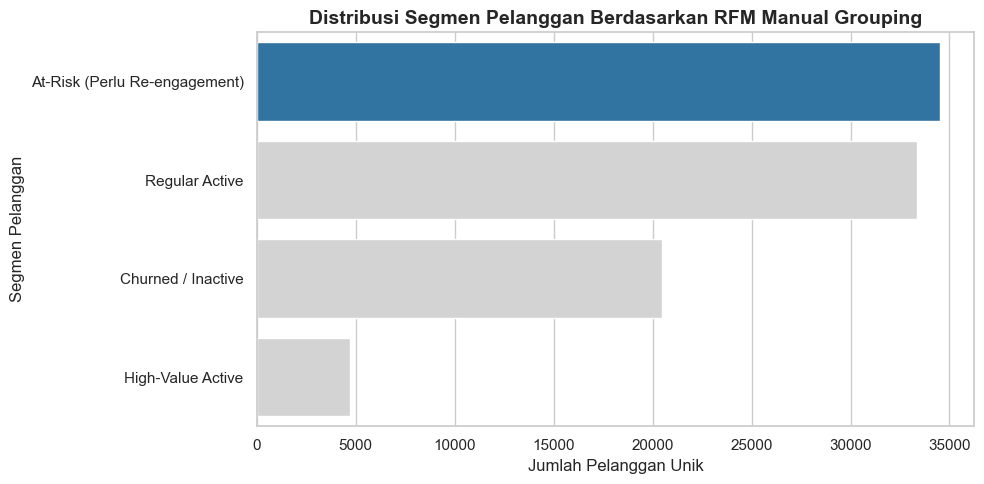

In [8]:
# Menghitung Recency, Frequency, dan Monetary per customer_unique_id
max_date = all_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = all_df.groupby("customer_unique_id", as_index=False).agg(
    max_order_timestamp=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
)
rfm_df["recency"] = (max_date - rfm_df["max_order_timestamp"]).dt.days

# Manual Grouping / Binning berdasarkan aturan bisnis pada nilai Recency & Monetary
def segment_customer(row):
    if row["recency"] <= 90 and row["monetary"] >= 150:
        return "High-Value Active"
    elif row["recency"] <= 180:
        return "Regular Active"
    elif row["recency"] <= 365:
        return "At-Risk (Perlu Re-engagement)"
    else:
        return "Churned / Inactive"

rfm_df["customer_segment"] = rfm_df.apply(segment_customer, axis=1)

segment_counts = rfm_df["customer_segment"].value_counts().reset_index()
segment_counts.columns = ["customer_segment", "total_customers"]

plt.figure(figsize=(10, 5))
colors_seg = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(segment_counts))]
sns.barplot(x="total_customers", y="customer_segment", data=segment_counts, palette=colors_seg)
plt.title("Distribusi Segmen Pelanggan Berdasarkan RFM Manual Grouping", fontsize=14, fontweight="bold")
plt.xlabel("Jumlah Pelanggan Unik")
plt.ylabel("Segmen Pelanggan")
plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan:**
- Mayoritas pelanggan hanya bertransaksi satu kali (`frequency = 1`), dan sebagian besar berada pada segmen **At-Risk** (91–365 hari sejak pembelian terakhir), yang menunjukkan perlunya program *retensi* dan *repeat order*.

## Conclusion & Recommendation

### Conclusion
1. **Kesimpulan Pertanyaan 1:** Selama periode Januari 2017 hingga Agustus 2018, kategori produk dengan total pendapatan (*revenue*) tertinggi adalah **`health_beauty`**, disusul oleh **`watches_gifts`** dan **`bed_bath_table`**. Sebaliknya, kategori dengan pendapatan terendah adalah **`security_and_services`**, **`fashion_childrens_clothes`**, dan **`cds_dvds_musicals`**.
2. **Kesimpulan Pertanyaan 2:** Di antara 10 negara bagian dengan volume pesanan tertinggi pada periode Januari 2017 hingga Agustus 2018, negara bagian **RJ (Rio de Janeiro)** dan **BA (Bahia)** mencatatkan persentase keterlambatan pengiriman tertinggi (lebih dari 11–12% pesanan terlambat), sedangkan **SP (São Paulo)** memiliki kinerja pengiriman paling tepat waktu.

### Recommendation (Action Items)
1. **Optimalisasi Stok & Kampanye Promosi Kategori Unggulan:** Tim *Merchandising* dan *Marketing* disarankan memprioritaskan ketersediaan stok (*safety stock*) serta mengalokasikan anggaran iklan utama pada 3 kategori penyumbang *revenue* terbesar (`health_beauty`, `watches_gifts`, `bed_bath_table`), serta menerapkan strategi *bundling* untuk kategori berkinerja rendah.
2. **Evaluasi Mitra Logistik & Penyesuaian Estimasi di Wilayah RJ dan BA:** Tim Operasional/Logistik perlu mengevaluasi SLA mitra ekspedisi pada rute menuju **Rio de Janeiro (RJ)** dan **Bahia (BA)**, menambah mitra pengiriman lokal di kedua negara bagian tersebut, serta mengkalibrasi ulang algoritma perhitungan `order_estimated_delivery_date` agar ekspektasi pelanggan lebih akurat.
3. **Program Retensi untuk Segmen At-Risk:** Mengirimkan voucher diskon pembelian kedua secara otomatis kepada pelanggan yang sudah tidak bertransaksi selama 90 hari guna meningkatkan nilai *Frequency* pada metrik RFM.